# From starlight to a planet score: the whole pipeline, step by step

**Goal.** Some stars get slightly dimmer for a few hours, again and again, at regular times. Sometimes that is a planet passing in front of the star. Often it is something else (a *fake*). We built a computer model that looks at each repeating dip and gives it a score from 0 (fake) to 1 (planet).

This notebook follows real stars through every step, with a picture for every idea.

In [1]:
import importlib, os, sys, time, warnings
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS']:
    os.environ.setdefault(var, '8')   # keep maths libraries from spreading over every core of a shared machine
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import lightkurve as lk
import torch
from astropy.timeseries import BoxLeastSquares
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from transitleastsquares import transit_mask
from IPython.display import display

START = time.time()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tls_masked_search').is_dir())
sys.path[:0] = [str(ROOT / 'tls_masked_search'), str(ROOT)]
from common import OUT_DIR, clean_and_stitch
from tess_hunt.search import phase_offset, vet_signal, weighted_mean
from tess_hunt.photometry import robust_sigma
m5 = importlib.import_module('05_build_dataset')      # download, search, the 12 measurements
m6 = importlib.import_module('06_train_classifier')   # labels, scoring helpers
m7 = importlib.import_module('07_build_views')        # the 6 snapshots
m8 = importlib.import_module('08_train_shape_model')  # the network
torch.set_num_threads(8)  # this tiny network runs slower when spread over every core of a big machine

%matplotlib inline
plt.rcParams.update({'figure.dpi': 80, 'axes.grid': True, 'grid.alpha': .2, 'axes.formatter.useoffset': False})

# One row per repeating dip found by the search; y = 1 for NASA planets, 0 for NASA fakes.
df = m6.load().reset_index(drop=True)
scores = pd.read_csv(OUT_DIR / 'shape_scores.csv')
df = df.merge(scores[['tic', 'signal', 'gbt', 'views', 'views_features', 'fold']], on=['tic', 'signal'])
npz = np.load(OUT_DIR / 'views.npz')
row_of = pd.Series(np.arange(len(npz['tic'])), index=pd.MultiIndex.from_arrays([npz['tic'], npz['signal']]))
df['view_row'] = row_of.loc[list(zip(df.tic, df.signal))].values
df['views_ok'] = npz['ok'][df.view_row]
hd = df[df.hard]                       # the hard set (see section 1)
hard = hd[hd.views_ok]

PLAIN = {   # the 12 measurements, in plain words
    'period': 'time between dips (days)',
    'duration_h': 'dip length (hours)',
    'depth_ppm': 'dip depth (parts per million)',
    'sde_per_transit': 'search peak height (per dip)',
    'depth_snr_per_transit': 'stands out from noise (per dip)',
    'pink_snr_per_transit': 'stands out from slow, wavy noise (per dip)',
    'odd_even_sigma': 'odd/even depth difference',
    'secondary_snr': 'halfway dip strength',
    'centroid_snr': 'star position shift',
    'transits_per_sector': 'dips seen per month',
    'significant_event_fraction': 'share of dips clear on their own',
    'chunk_fraction': 'share of data blocks that found it',
}
assert list(PLAIN) == m6.DIP_FEATURES
VERDICT = {'CP': 'confirmed planet', 'KP': 'known planet', 'FP': 'fake', 'FA': 'fake'}
EX = {'A': 273874849, 'B': 96291218, 'C': 279999655, 'D': 349790953}
ex = {k: df[(df.tic == tic) & (df.signal == 1)].iloc[0] for k, tic in EX.items()}
COLORS = {'A': 'tab:green', 'B': 'tab:orange', 'C': 'tab:red', 'D': 'tab:purple'}
paths = {k: m7.capped(sorted(str(p) for p in m7.RAW.glob(f'*{tic:016d}*'))) for k, tic in EX.items()}


def flow(ax, labels, y=0.5, h=0.6, fc='#e8f0fa'):
    # Draw labelled boxes left to right, joined by arrows.
    for i, lab in enumerate(labels):
        ax.add_patch(FancyBboxPatch((i + 0.06, y - h / 2), 0.88, h, boxstyle='round,pad=0.02', fc=fc, ec='0.4'))
        ax.text(i + 0.5, y, lab, ha='center', va='center', fontsize=9)
        if i < len(labels) - 1:
            ax.annotate('', xy=(i + 1.05, y), xytext=(i + 0.95, y), arrowprops=dict(arrowstyle='->', lw=1.5))
    ax.set_xlim(0, len(labels)); ax.axis('off')

assert scores.groupby('tic').fold.nunique().max() == 1   # stored groups split by star
print(f'{len(df)} labelled dips; hard set: {len(hd)} dips ({hd.y.sum()} NASA planets, {(hd.y == 0).sum()} NASA fakes)')
extra = len(scores) - scores.merge(df[['tic', 'signal']]).shape[0]
if extra:
    print(f'note: the stored pipeline scores come from a run that also trained on {extra} extra dips '
          f'(easy fakes) that the current labels leave out; the hard-set dips are the same.')

1743 labelled dips; hard set: 1743 dips (1112 NASA planets, 631 NASA fakes)


## Two kinds of input: pictures and numbers

The model is given two different things about each dip. They are easy to mix up, so here they are side by side:

- **Snapshots = pictures.** Each one is a curve: the dip's brightness drawn as 61 (or 201) points. There are **6** snapshots per dip.
- **Measurements = single numbers.** Each one is one value, like "dip depth = 1.9%". There are **12** measurements per dip.

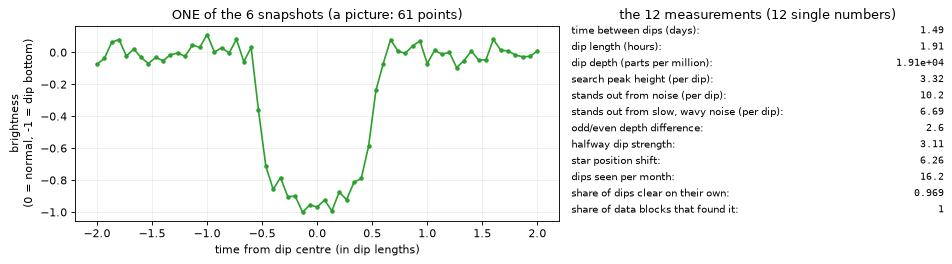

In [2]:
A = ex['A']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1.3, 1]})
a1.plot(np.linspace(-2, 2, m7.LOCAL_BINS), npz['local'][A.view_row], 'o-', ms=3, color=COLORS['A'])
a1.set(title='ONE of the 6 snapshots (a picture: 61 points)', xlabel='time from dip centre (in dip lengths)',
       ylabel='brightness\n(0 = normal, -1 = dip bottom)')
a2.axis('off')
a2.set_title('the 12 measurements (12 single numbers)')
for i, (col, name) in enumerate(PLAIN.items()):
    a2.text(0, 1 - i / 12, f'{name}:', fontsize=9, va='top')
    a2.text(1, 1 - i / 12, f'{A[col]:.3g}', fontsize=9, va='top', ha='right', family='monospace')
plt.tight_layout(); plt.show()

## The whole pipeline on one page

1. **Download**: TESS (a NASA space telescope) measures each star's brightness every 2 minutes, for about a month at a time. One month of data is called a *sector*. We use up to 8 sectors per star.
2. **Clean**: remove slow brightness drifts and bad points.
3. **Search**: try thousands of possible periods (time between dips) and find the one where dips line up best. The tool is called **TLS** (Transit Least Squares).
4. **Search again**: hide the dips just found and search once more, to catch a second, weaker signal. We keep up to 3 signals per star.
5. **Describe each dip**: (a) make the **6 snapshots** (pictures); (b) compute the **12 measurements** (numbers).
6. **Model**: a neural network reads both and gives a score from 0 to 1.
7. **Ranked list**: sort all dips by score; the top ones are the best planet candidates to check by hand.

**Where do NASA's answers come in?** NASA keeps a list of dips it has checked and labelled "planet" or "fake". We match our dips to it by period. Those labels are used **only** to train the model and to grade it. They are never an input.

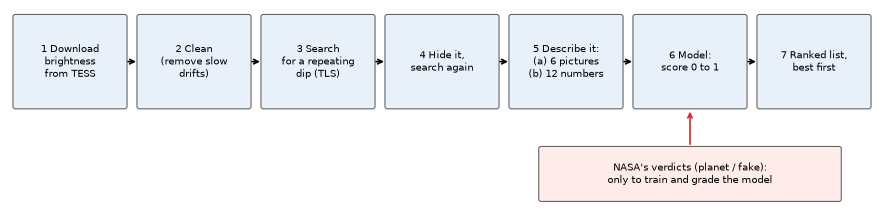

In [3]:
fig, ax = plt.subplots(figsize=(14, 3.2))
flow(ax, ['1 Download\nbrightness\nfrom TESS', '2 Clean\n(remove slow\ndrifts)', '3 Search\nfor a repeating\ndip (TLS)',
          '4 Hide it,\nsearch again', '5 Describe it:\n(a) 6 pictures\n(b) 12 numbers', '6 Model:\nscore 0 to 1',
          '7 Ranked list,\nbest first'], y=1.2, h=0.75)
ax.add_patch(FancyBboxPatch((4.3, 0.05), 2.4, 0.42, boxstyle='round,pad=0.02', fc='#fdecea', ec='0.4'))
ax.text(5.5, 0.26, "NASA's verdicts (planet / fake):\nonly to train and grade the model", ha='center', va='center', fontsize=9)
ax.annotate('', xy=(5.5, 0.8), xytext=(5.5, 0.49), arrowprops=dict(arrowstyle='->', lw=1.5, color='tab:red'))
ax.set_ylim(0, 1.65)
plt.show()

*Where we are: **stage overview** (all stages).*


## 1. Our examples

We use the **hard set**: dips that NASA itself checked and labelled, either a real planet or a fake. (We leave out easy fakes, like plain noise, which nobody would mistake for a planet.)

Every score shown below comes from a model that **never saw that star**. The stars were split into 5 groups; each group was scored by a model trained on the other 4. Each example was scored by the model that never saw its star.

- **A**: a known planet with a big, clear dip.
- **B**: a fake: two stars orbiting each other, which also dim each other halfway round the orbit.
- **C**: a fake: the star's measured position moves during every dip, so the dip really comes from a neighbouring star.
- **D**: a fake used only in section 6: every other dip is deeper (two stars of different sizes).

In [4]:
table = pd.DataFrame.from_dict(orient='index', data={k: {
    'star (catalogue number)': r.tic,
    'period (days)': round(r.period, 2),
    'dip depth (%)': round(r.depth_ppm / 1e4, 2),
    'dip length (hours)': round(r.duration_h, 1),
    'NASA verdict': VERDICT[r.label],
    'tree score (numbers only)': round(r.gbt, 4),
    'shape-model score': round(r.views_features, 4)} for k, r in ex.items()})
display(table)
assert [r.y for r in ex.values()] == [1, 0, 0, 0]
assert ex['A'].gbt < 0.5 < ex['A'].views_features
assert all(ex[k].gbt < 0.5 and ex[k].views_features < 0.5 for k in 'BCD')

,star (catalogue number),period (days),dip depth (%),dip length (hours),NASA verdict,tree score (numbers only),shape-model score
A,273874849,1.49,1.91,1.9,known planet,0.2574,0.9027
B,96291218,13.71,0.15,5.8,fake,0.0147,0.0085
C,279999655,1.54,0.41,1.9,fake,0.2795,0.0078
D,349790953,1.55,0.26,4.1,fake,0.0039,0.0251


"Tree score" comes from a simpler model that only sees the 12 numbers. Both scores here are the pipeline's stored results. For **A**, the tree score is low (it calls A a fake) and the shape-model score is high. **The simpler model got A wrong; the shape model got it right.** Both models call B, C and D fakes (the `assert` checks all of this).

*Where we are: **stage 1 and 2** (download and clean).*


## 2. The raw data (example A)

Here is one month (one sector) of star A's brightness, measured every 2 minutes.

star A: 6 sectors (months) of data


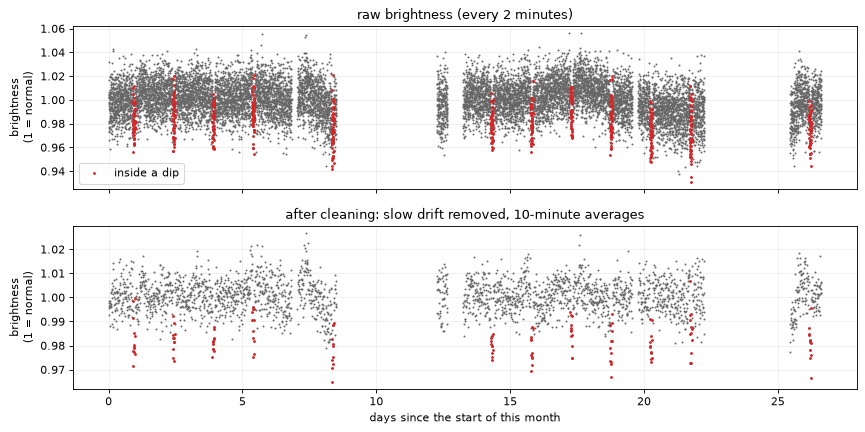

In [5]:
P, T0, DUR = A.period, A.t0, A.duration_h / 24          # days
lcs = {k: [lk.read(p, flux_column='pdcsap_flux') for p in paths[k]] for k in 'ABC'}
print(f"star A: {len(lcs['A'])} sectors (months) of data")

def near_dip(t, half):
    return np.abs(phase_offset(t, P, T0)) < half      # True within `half` days of a dip centre

month = lcs['A'][0]
raw = month.remove_nans().normalize()
t_raw, f_raw = raw.time.value, raw.flux.value
t_cl, f_cl, _ = clean_and_stitch([month], bin_minutes=10, ephemeris=(P, T0, DUR))
t_cl, f_cl = np.asarray(t_cl), np.ma.filled(f_cl, np.nan)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, t, f, title in [(axes[0], t_raw, f_raw, 'raw brightness (every 2 minutes)'),
                        (axes[1], t_cl, f_cl, 'after cleaning: slow drift removed, 10-minute averages')]:
    d = near_dip(t, DUR / 2)
    ax.plot(t - t_raw[0], f, '.', ms=1.5, color='0.4')
    ax.plot(t[d] - t_raw[0], f[d], '.', ms=3, color='tab:red', label='inside a dip')
    ax.set(title=title, ylabel='brightness\n(1 = normal)')
axes[0].legend(loc='lower left')
axes[1].set_xlabel('days since the start of this month')
plt.tight_layout(); plt.show()

The raw brightness drifts slowly. That comes from the star itself (spots, rotation) and from the telescope (pointing, temperature). The drift is much slower than a 2-hour dip.

So cleaning fits a smooth curve over about a day and a half and divides it out. It skips the dips, so they aren't flattened away. What remains: a flat line at 1, with short dips about 2% deep, every 1.49 days.

*Where we are: **stage 3** (search).*


## 3. The search: which period makes the dips line up?

The search tries thousands of periods, from half a day to 30 days. For each one it asks: "if dips repeat this often, how much dimmer is the star at those times?" The answer is a **strength** for every period. A real repeating dip gives one tall, sharp peak.

The real search uses TLS, which tests a planet-shaped dip. Below, to keep this fast, we use its simpler cousin **BLS** (Box Least Squares), which tests a box-shaped dip, on star A's first block of consecutive months.

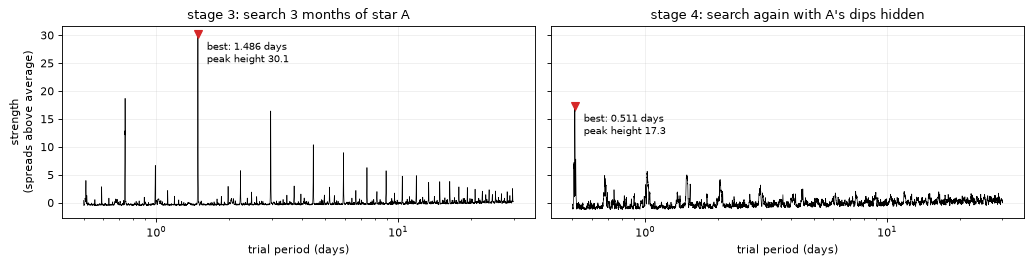

search result stored for A: period 1.4857 days; TLS peak height (best block) 32.7


In [6]:
block = m5.chunks(paths['A'])[0]                       # first block of consecutive sectors
t_b, y_b, dy_b = m5.stitched(block)                    # cleaned, 10-minute points, as the search used
PERIODS = np.geomspace(m5.PERIOD_RANGE[0], min(m5.PERIOD_RANGE[1], np.ptp(t_b) / 2), 20000)

def strength(t, y, dy):
    # Box-search strength at every trial period, in 'spreads above average' (so the peak height = SDE)
    p = BoxLeastSquares(t, y, dy).power(PERIODS, np.array([1, 2, 3, 4, 6]) / 24).power
    return (p - p.mean()) / p.std()

s1 = strength(t_b, y_b, dy_b)
hide = transit_mask(t_b, P, max(2 * DUR, m5.MIN_HIDE_DAYS), T0)   # stage 4: hide the dips found
s2 = strength(t_b[~hide], y_b[~hide], dy_b[~hide])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, s, title in [(axes[0], s1, f'stage 3: search {len(block)} months of star A'),
                     (axes[1], s2, "stage 4: search again with A's dips hidden")]:
    ax.plot(PERIODS, s, lw=.6, color='k')
    i = s.argmax()
    ax.plot(PERIODS[i], s[i], 'v', color='tab:red', ms=8)
    ax.annotate(f'best: {PERIODS[i]:.3f} days\npeak height {s[i]:.1f}', (PERIODS[i], s[i]), xytext=(8, -25),
                textcoords='offset points', fontsize=9)
    ax.set(xscale='log', title=title, xlabel='trial period (days)')
axes[0].set_ylabel('strength\n(spreads above average)')
plt.tight_layout(); plt.show()
print(f"search result stored for A: period {P:.4f} days; TLS peak height (best block) {A.best_chunk_sde:.1f}")

- Left: one tall peak at 1.486 days, A's period. Smaller peaks at simple fractions and multiples of it (half, double...) are echoes of the same dips.
- Right: after hiding A's dips and searching again (stage 4), that peak and its echoes are gone. Whatever is tallest now (here a much lower peak near the shortest periods tried) becomes the next signal. Many such leftovers are noise, which is one reason we need a model to judge them.

The **peak height** is measured in "spreads": how many times the typical up-and-down of the whole chart the peak rises above its average. Astronomers call it **SDE** (signal detection efficiency). It becomes one of the 12 measurements.

*Where we are: **stage 5a** (describe the dip: pictures).*


## 4. Folding: stacking all the dips on top of each other

One dip on its own is noisy. But now we know the period. So we can cut the data every 1.49 days and lay all the dips on top of each other, lined up on the dip centre. This is called **folding**.

102 dips with data, 22580 points inside the close-up window


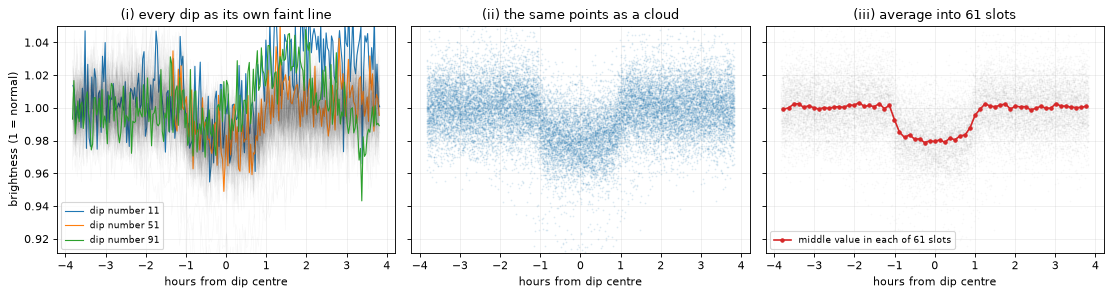

In [7]:
def cleaned_all(lc_list, period, t0, dur):
    # Same cleaning as the snapshot builder: each sector cleaned on its own, 2-minute points
    parts = [clean_and_stitch([lc], bin_minutes=2, ephemeris=(period, t0, dur)) for lc in lc_list]
    t = np.concatenate([np.asarray(p[0]) for p in parts])
    f = np.concatenate([np.ma.filled(p[1], np.nan) for p in parts])
    ok = np.isfinite(t) & np.isfinite(f)
    return t[ok], f[ok]

t, f = cleaned_all(lcs['A'], P, T0, DUR)
dt = phase_offset(t, P, T0)                  # days from the nearest dip centre
cycle = np.round((t - T0) / P).astype(int)   # which dip each point belongs to
W = m7.HALF_WINDOW * DUR                     # close-up window: +/- 2 dip lengths
win = np.abs(dt) < W
print(f'{len(np.unique(cycle[win]))} dips with data, {win.sum()} points inside the close-up window')

base = np.median(f[np.abs(dt) > DUR])        # normal brightness, measured away from the dips
local_raw, _ = m7.binned(dt, f, -W, W, m7.LOCAL_BINS)       # middle value in each of 61 time slots
edges = np.linspace(-W, W, m7.LOCAL_BINS + 1)
centres_h = (edges[:-1] + edges[1:]) / 2 * 24

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for n, k in enumerate(np.unique(cycle[win])):
    s = win & (cycle == k)
    axes[0].plot(dt[s] * 24, f[s], lw=.5, alpha=.04, color='0.3')
    if n in (10, 50, 90):   # three single dips, drawn strongly: each alone is mostly noise
        axes[0].plot(dt[s] * 24, f[s], lw=1, color=f'C{n // 40}', label=f'dip number {n + 1}')
axes[0].set_title('(i) every dip as its own faint line')
axes[0].legend(loc='lower left', fontsize=8)
axes[1].plot(dt[win] * 24, f[win], '.', ms=1, alpha=.15, color='tab:blue')
axes[1].set_title('(ii) the same points as a cloud')
axes[2].plot(dt[win] * 24, f[win], '.', ms=1, alpha=.06, color='0.6')
axes[2].plot(centres_h, local_raw, 'o-', ms=3, color='tab:red', label='middle value in each of 61 slots')
axes[2].set_title('(iii) average into 61 slots')
axes[2].legend(loc='lower left', fontsize=8)
axes[0].set_ylabel('brightness (1 = normal)')
for ax in axes:
    ax.set_xlabel('hours from dip centre')
axes[0].set_ylim(np.percentile(f[win], [0.2, 99.9]))
plt.tight_layout(); plt.show()

Each single dip is lost in noise. But noise is random: some points land high, some low. Stack about a hundred dips, take the middle value in each small time slot, and the noise cancels while the real shape stays.

The result is a clean 61-point curve: the **close-up snapshot**.

The network gets the close-up **rescaled**: normal brightness becomes 0 and the dip bottom becomes -1. The **whole-orbit snapshot** is the same idea over one full orbit, in 201 slots. It is there to show anything happening *away* from the dip.

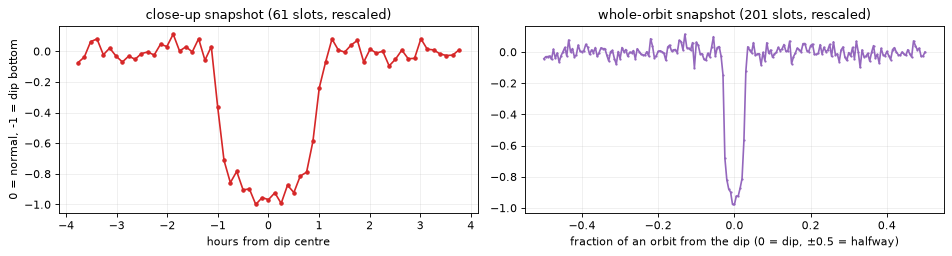

In [8]:
close_up = (local_raw - base) / (base - local_raw.min())
glob_raw, _ = m7.binned(dt / P, f, -0.5, 0.5, m7.GLOBAL_BINS)    # the whole orbit in 201 slots
whole = (glob_raw - base) / (base - local_raw.min())
assert np.allclose(close_up, npz['local'][A.view_row], atol=1e-5)  # identical to the model's input
assert np.allclose(whole, npz['global'][A.view_row], atol=1e-5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].plot(centres_h, close_up, 'o-', ms=3, color='tab:red')
axes[0].set(title='close-up snapshot (61 slots, rescaled)', xlabel='hours from dip centre', ylabel='0 = normal, -1 = dip bottom')
axes[1].plot(np.linspace(-0.5, 0.5, m7.GLOBAL_BINS), whole, '.-', ms=2, color='tab:purple')
axes[1].set(title='whole-orbit snapshot (201 slots, rescaled)', xlabel='fraction of an orbit from the dip (0 = dip, ±0.5 = halfway)')
plt.tight_layout(); plt.show()

The `assert` lines check that what we just built by hand is exactly what the network is fed.

*Where we are: **stage 5a** (describe the dip: pictures).*


## 5. The six snapshots

Besides the whole orbit and the close-up, there are four more close-ups of the same 61 time slots:

- **odd** / **even**: only dips 1, 3, 5... / only dips 2, 4, 6...
- **halfway**: the same window, but centred half an orbit after the dip.
- **star position**: how much the star's measured position on the camera moves during the dip. Its flat level sits a bit above 0 for every star (a side effect of how it is measured); what matters is a rise during the dip.

Here are all six for A, B and C, rebuilt from the raw files with the pipeline's own code and checked against the stored ones.

rebuilt snapshots match the stored ones for A, B and C


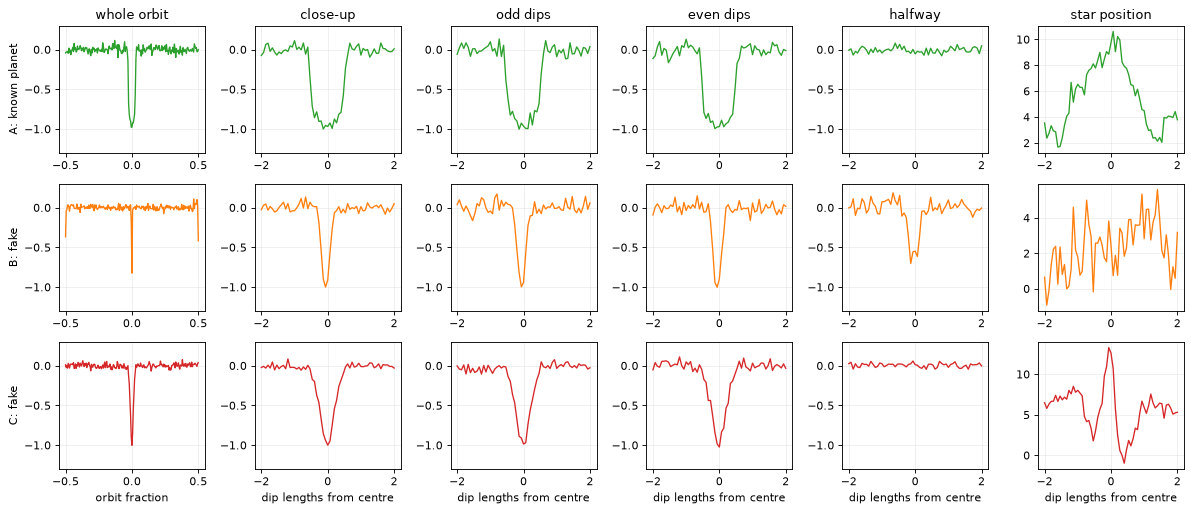

In [9]:
NAMES = {'global': 'whole orbit', 'local': 'close-up', 'odd': 'odd dips', 'even': 'even dips',
         'secondary': 'halfway', 'centroid': 'star position'}
snap = {}
for k in 'ABC':
    r = ex[k]
    snap[k], ok = m7.signal_views(lcs[k], r.period, r.t0, r.duration_h / 24)
    assert ok
    for name in NAMES:
        assert np.allclose(snap[k][name], npz[name][r.view_row], atol=1e-4), (k, name)
print('rebuilt snapshots match the stored ones for A, B and C')

x_local = np.linspace(-2, 2, m7.LOCAL_BINS)   # in dip lengths
fig, axes = plt.subplots(3, 6, figsize=(15, 6.5))
for i, k in enumerate('ABC'):
    for j, name in enumerate(NAMES):
        ax = axes[i, j]
        x = np.linspace(-0.5, 0.5, m7.GLOBAL_BINS) if name == 'global' else x_local
        ax.plot(x, snap[k][name], color=COLORS[k], lw=1.2)
        if name != 'centroid':
            ax.set_ylim(-1.3, 0.3)
        if i == 0:
            ax.set_title(NAMES[name])
        if i == 2:
            ax.set_xlabel('orbit fraction' if name == 'global' else 'dip lengths from centre')
    axes[i, 0].set_ylabel(f'{k}: {VERDICT[ex[k].label]}')
plt.tight_layout(); plt.show()

| snapshot | what it shows | the fake it helps catch |
|---|---|---|
| whole orbit | the full orbit, dip in the middle | two stars: a second dip at the edges (halfway round) |
| close-up | the dip's shape | two stars: a **V** shape. A planet gives a flat-bottomed **U**, because it sits fully in front of the star for a while |
| odd / even | alternate dips separately | two stars of different sizes: every other dip has a different depth |
| halfway | half an orbit after the dip | two stars: when the dimmer star is hidden, there is a small second dip |
| star position | movement of the star's measured position | a neighbouring star: the light's centre shifts towards the star that is really dimming |

What to see above:
- **A** (planet): U-shaped dip with a flat floor; odd and even match; halfway is flat; the position moves a little.
- **B** (two stars): a narrow dip, and a clear **halfway dip** about 70% as deep (also at the edges of the whole-orbit picture).
- **C** (neighbour): a pointy dip, and the **position rises sharply** exactly during the dip.

Note A's position picture also rises (to about 10), nearly as high as C's (about 13). A big dip on a star with neighbours nudges the measured centre a little, and this picture's height also depends on how much data there is. The matching *measurement* tells them apart much better (A: 6, C: 56; section 6).

**Why rescale?** A 2% dip and a 0.1% dip both end up going from 0 to -1. So the pictures show **shape only, not size**. Size is given separately, as a measurement.

### The average planet vs the average fake

Average each snapshot over all NASA planets, and over all NASA fakes, in the hard set.

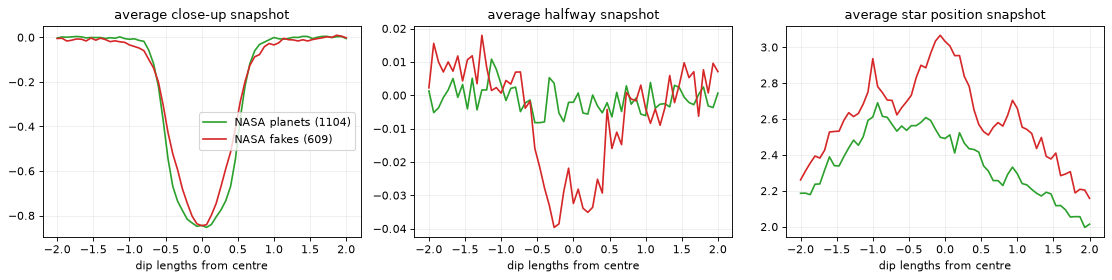

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for name, ax in zip(['local', 'secondary', 'centroid'], axes):
    for y, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        rows = hard.view_row[hard.y == y].values
        ax.plot(x_local, npz[name][rows].mean(0), color=c, label=f'{lab} ({len(rows)})')
    ax.set(title=f'average {NAMES[name]} snapshot', xlabel='dip lengths from centre')
axes[0].legend()
plt.tight_layout(); plt.show()

- **Close-up**: the average planet has a slightly wider, flatter bottom (U). The average fake is more pointed (V), with wider sloping sides.
- **Halfway**: flat for planets; a small dip for fakes (from the two-star pairs among them).
- **Star position**: fakes move more during the dip.

These are averages. Single planets and fakes overlap a lot, which is why this is the hard set.

*Where we are: **stage 5b** (describe the dip: numbers).*


## 6. The 12 measurements, one at a time

The search's checking code (`tess_hunt.search.vet_signal`) measures each dip on 10-minute data. Below we rerun it on our examples and check it gives exactly the stored numbers.

Some measurements are given **per dip**: divided by the square root of the number of dips. Why? Combining more dips makes any signal look stronger (noise shrinks like 1/√(number of dips)). And NASA watches planet stars longer, so they have more dips. Without this correction, the model could learn "more data means planet", which is useless. Dividing by √(dips) gives roughly the strength of one typical dip.

re-measured values match the stored ones for A, B, C and D


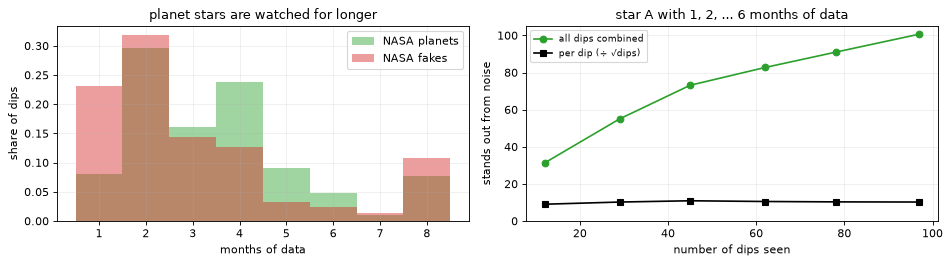

In [11]:
def measure_data(path_list):
    # The 10-minute data the measurements are made on (as in 05_build_dataset.search_star), per sector
    parts = []
    for p in path_list:
        try:
            parts.append(m5.preprocess(p, m5.CONFIG)[0])
        except ValueError:          # sector rejected by the quality checks
            pass
    return {k: np.concatenate([d[k] for d in parts]) for k in ['time', 'flux', 'error', 'centroid1', 'centroid2']}, parts

mdata, mparts, vet = {}, {}, {}
for k, r in ex.items():
    mdata[k], mparts[k] = measure_data(paths[k])
    vet[k] = vet_signal(mdata[k], r.period, r.t0, r.duration_h / 24)
    for col in ['depth_ppm', 'depth_snr', 'pink_snr', 'odd_even_sigma', 'secondary_snr', 'centroid_snr',
                'observed_transits', 'significant_events']:
        assert np.isclose(vet[k][col], r[col]), (k, col)
print('re-measured values match the stored ones for A, B, C and D')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for y, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
    g = hd[hd.y == y]
    axes[0].hist(g.sectors, np.arange(0.5, 9.5), weights=np.full(len(g), 1 / len(g)), alpha=.45, color=c, label=lab)

# Star A measured on its first 1, 2, ... 6 months of data
grow = []
for n in range(1, len(mparts['A']) + 1):
    part = {k: np.concatenate([d[k] for d in mparts['A'][:n]]) for k in mdata['A']}
    v = vet_signal(part, A.period, A.t0, A.duration_h / 24)
    grow.append((v['observed_transits'], v['depth_snr']))
grow = np.array(grow)
axes[1].plot(grow[:, 0], grow[:, 1], 'o-', color=COLORS['A'], label='all dips combined')
axes[1].plot(grow[:, 0], grow[:, 1] / np.sqrt(grow[:, 0]), 's-', color='k', label='per dip (÷ √dips)')
axes[1].legend(fontsize=8)
axes[0].set(title='planet stars are watched for longer', xlabel='months of data', ylabel='share of dips')
axes[1].set(title='star A with 1, 2, ... 6 months of data', xlabel='number of dips seen', ylabel='stands out from noise',
            ylim=(0, None))
axes[0].legend()
plt.tight_layout(); plt.show()

### Group 1: the dip itself

- **Time between dips (period), days.** How long one orbit takes. Very short periods are common for two-star pairs.
- **Dip length, hours.** How long the dimming lasts. For a planet it follows from the star's size and the orbit; a dip that is too long or too short for the period is suspicious.
- **Dip depth, parts per million (ppm).** How much dimmer the star gets: 10,000 ppm = 1%. A planet can only block so much light: very deep dips (several %) are usually two stars.

Top: what they mean on star A. Bottom: how often each value occurs for NASA planets vs NASA fakes (dashed lines: our examples).

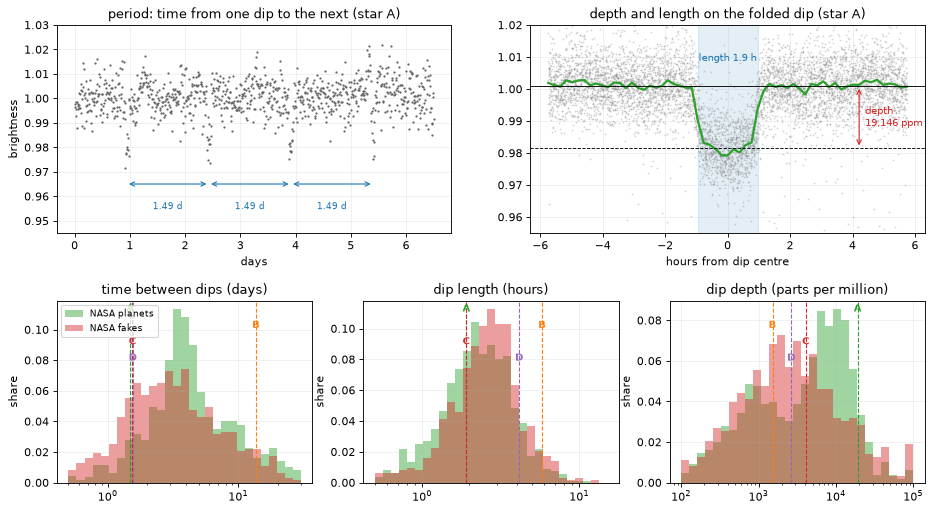

In [12]:
def class_hist(ax, col, lo, hi, log=False):
    # Share of NASA planets / fakes (hard set) at each value of one measurement; examples marked
    v = hd[col].replace([np.inf, -np.inf], np.nan)
    bins = np.geomspace(lo, hi, 30) if log else np.linspace(lo, hi, 30)
    for y, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        x = v[hd.y == y].dropna().clip(lo, hi)
        ax.hist(x, bins, weights=np.full(len(x), 1 / len(x)), alpha=.45, color=c, label=lab)
    for n, (k, r) in enumerate(ex.items()):
        if np.isfinite(r[col]):
            ax.axvline(np.clip(r[col], lo, hi), color=COLORS[k], ls='--', lw=1)
            ax.text(np.clip(r[col], lo, hi), ax.get_ylim()[1] * (.94 - .09 * n), k, color=COLORS[k], fontsize=9,
                    ha='center', fontweight='bold')
    ax.set(xscale='log' if log else 'linear', title=PLAIN[col], ylabel='share')

fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['period', 'shape']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['period', 'duration_h', 'depth_ppm']], gridspec_kw={'top': .42, 'bottom': .07})

ax = top['period']
d = np.flatnonzero(t_cl < t_cl[0] + 6.5)
ax.plot(t_cl[d] - t_raw[0], f_cl[d], '.', ms=2, color='0.4')
centres = T0 + P * np.arange(np.ceil((t_cl[0] - T0) / P), np.floor((t_cl[d[-1]] - T0) / P) + 1)
for c0, c1 in zip(centres[:-1], centres[1:]):
    ax.annotate('', xy=(c1 - t_raw[0], 0.965), xytext=(c0 - t_raw[0], 0.965), arrowprops=dict(arrowstyle='<->', color='tab:blue'))
    ax.text((c0 + c1) / 2 - t_raw[0], 0.958, f'{P:.2f} d', ha='center', va='top', fontsize=8, color='tab:blue')
ax.set(title='period: time from one dip to the next (star A)', xlabel='days', ylabel='brightness', ylim=(0.945, 1.03))

ax = top['shape']
dm = mdata['A']
x = phase_offset(dm['time'], P, T0) * 24
w = np.abs(x) < 3 * A.duration_h
ax.plot(x[w], dm['flux'][w], '.', ms=1.5, alpha=.25, color='0.5')
b, _ = m7.binned(x[w], dm['flux'][w], -3 * A.duration_h, 3 * A.duration_h, 61)
ax.plot(np.linspace(-3, 3, 61) * A.duration_h, b, color=COLORS['A'], lw=2)
base_A = np.median(dm['flux'][np.abs(x) > A.duration_h])
ax.axhline(base_A, color='k', lw=.8); ax.axhline(base_A - A.depth_ppm / 1e6, color='k', lw=.8, ls='--')
ax.annotate('', xy=(2.2 * A.duration_h, base_A - A.depth_ppm / 1e6), xytext=(2.2 * A.duration_h, base_A),
            arrowprops=dict(arrowstyle='<->', color='tab:red'))
ax.text(2.25 * A.duration_h, base_A - A.depth_ppm / 2e6, f' depth\n {A.depth_ppm:,.0f} ppm', color='tab:red', va='center', fontsize=9)
ax.axvspan(-A.duration_h / 2, A.duration_h / 2, color='tab:blue', alpha=.12)
ax.text(0, base_A + 0.008, f'length {A.duration_h:.1f} h', color='tab:blue', ha='center', fontsize=9)
ax.set(title='depth and length on the folded dip (star A)', xlabel='hours from dip centre', ylim=(0.955, 1.02))

class_hist(bottom['period'], 'period', 0.5, 30, log=True)
class_hist(bottom['duration_h'], 'duration_h', 0.5, 15, log=True)
class_hist(bottom['depth_ppm'], 'depth_ppm', 100, 1e5, log=True)
bottom['period'].legend(fontsize=8, loc='upper left')
plt.show()

In this hard set, NASA's planets are often *deeper* than the fakes (many are big, well-known planets). The fakes include many shallow dips. Each of these three numbers alone separates planets and fakes only a little.

### Group 2: how clearly the dip stands out

- **Search peak height (SDE), per dip.** How far the best period's peak rises above the rest of the search chart (section 3). Tall = the period is clearly real.
- **Stands out from noise (depth SNR), per dip.** Dip depth divided by how uncertain that depth is (SNR = signal-to-noise ratio). This uncertainty assumes the noise is random from one 10-minute point to the next.
- **Stands out from slow, wavy noise (pink SNR), per dip.** The same, but the noise is measured by averaging the data in dip-length blocks. If the brightness wobbles slowly, those block averages scatter more than random noise would predict, and the dip counts as less certain. Slow wobbles can fake a dip; this number guards against that.

Faint, uncertain dips are more often fakes (or nothing at all).

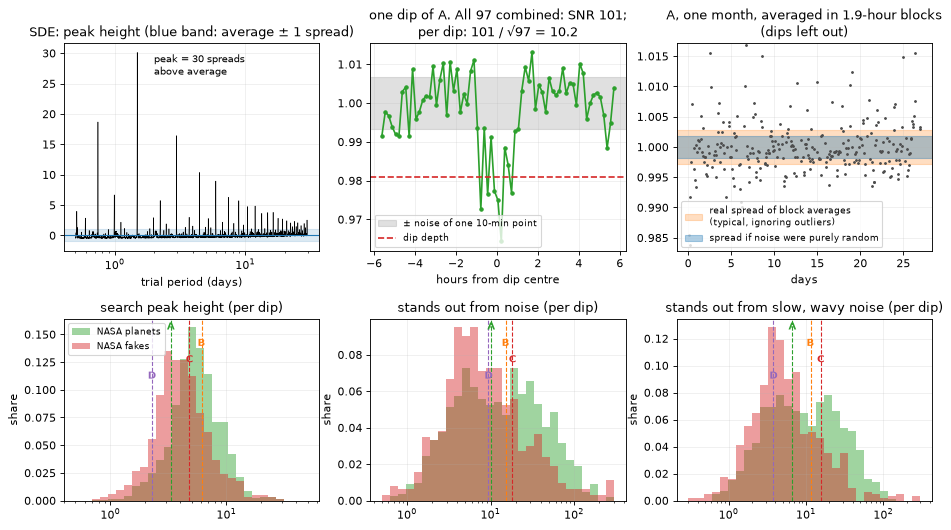

A: wavy-noise spread is 1.6x the purely random spread, so its pink SNR (66) is lower than its plain SNR (101)


In [13]:
fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['sde', 'snr', 'pink']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['sde_per_transit', 'depth_snr_per_transit', 'pink_snr_per_transit']],
                            gridspec_kw={'top': .42, 'bottom': .07})

ax = top['sde']
ax.plot(PERIODS, s1, lw=.5, color='k')
ax.axhline(0, color='tab:blue', lw=1); ax.axhspan(-1, 1, color='tab:blue', alpha=.15)
ax.annotate(f'peak = {s1.max():.0f} spreads\nabove average', (PERIODS[s1.argmax()], s1.max()), xytext=(15, -20),
            textcoords='offset points', fontsize=9)
ax.set(xscale='log', title='SDE: peak height (blue band: average ± 1 spread)', xlabel='trial period (days)')

ax = top['snr']
dm = mdata['A']; ph = phase_offset(dm['time'], P, T0); cyc = np.rint((dm['time'] - T0) / P).astype(int)
ev = vet['A']['events'][len(vet['A']['events']) // 2]          # one typical dip
one = (cyc == ev['cycle']) & (np.abs(ph) < 3 * DUR)
noise = robust_sigma(dm['flux'][np.abs(ph) > DUR])
ax.plot(ph[one] * 24, dm['flux'][one], 'o-', ms=3, color=COLORS['A'])
ax.axhspan(1 - noise, 1 + noise, color='0.6', alpha=.3, label='± noise of one 10-min point')
ax.axhline(1 - A.depth_ppm / 1e6, color='tab:red', ls='--', label='dip depth')
ax.legend(fontsize=8, loc='lower left')
n_dips = vet['A']['observed_transits']
ax.set(title=f'one dip of A. All {n_dips} combined: SNR {A.depth_snr:.0f};\nper dip: {A.depth_snr:.0f} / √{n_dips} = {A.depth_snr_per_transit:.1f}',
       xlabel='hours from dip centre')

ax = top['pink']
out = np.abs(ph) > DUR
labels = np.floor((dm['time'] - dm['time'].min()) / max(DUR, .025)).astype(int)   # dip-length blocks, as vet_signal
blk = []   # (time, average brightness, its uncertainty if the noise were purely random) per block
for lab in np.unique(labels):
    b = (labels == lab) & out
    if b.sum() >= 3:
        blk.append((dm['time'][b].mean(), *weighted_mean(dm['flux'][b], dm['error'][b])))
blk = np.array(blk)
block_noise = robust_sigma(blk[:, 1])
white = np.median(blk[:, 2])
depth_err = (A.depth_ppm / 1e6) / A.depth_snr
assert np.isclose(A.depth_ppm / 1e6 / max(depth_err, block_noise / np.sqrt(n_dips)), A.pink_snr)
first = blk[:, 0] < blk[0, 0] + 27
ax.plot(blk[first, 0] - blk[0, 0], blk[first, 1], '.', ms=3, color='0.3')
ax.axhspan(1 - block_noise, 1 + block_noise, color='tab:orange', alpha=.25, label='real spread of block averages\n(typical, ignoring outliers)')
ax.axhspan(1 - white, 1 + white, color='tab:blue', alpha=.35, label='spread if noise were purely random')
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'A, one month, averaged in {A.duration_h:.1f}-hour blocks\n(dips left out)', xlabel='days',
       ylim=(1 - 6 * block_noise, 1 + 6 * block_noise))

class_hist(bottom['sde_per_transit'], 'sde_per_transit', 0.5, 50, log=True)
class_hist(bottom['depth_snr_per_transit'], 'depth_snr_per_transit', 0.5, 300, log=True)
class_hist(bottom['pink_snr_per_transit'], 'pink_snr_per_transit', 0.3, 300, log=True)
bottom['sde_per_transit'].legend(fontsize=8, loc='upper left')
plt.show()
print(f'A: wavy-noise spread is {block_noise / white:.1f}x the purely random spread, '
      f'so its pink SNR ({A.pink_snr:.0f}) is lower than its plain SNR ({A.depth_snr:.0f})')

The SDE chart here is the quick box search from section 3; the stored SDE comes from the real TLS search, so the numbers differ. The middle and right pictures use the exact data and noise rules of the stored measurements (the `assert` recomputes A's pink SNR from them).

Planets in the hard set tend to stand out more clearly than fakes, on all three numbers.

### Group 3: warning signs of a fake

- **Odd/even depth difference.** Compare the average depth of odd dips (1, 3, 5...) with even dips (2, 4, 6...). Given in "sigmas": the difference divided by its uncertainty, so 3 or more means "real difference". A planet blocks the same light every time. Two stars of different sizes give alternating depths (and the search may have found half the true period).
- **Halfway dip strength.** How much dimmer the star is exactly half an orbit after the dip, divided by its uncertainty. A planet gives almost nothing there; a two-star pair often gives a second dip.
- **Star position shift.** TESS also records where the star's light is centred on the camera. If that centre moves during every dip, the dimming is really on a nearby star whose light overlaps. Also in "sigmas".

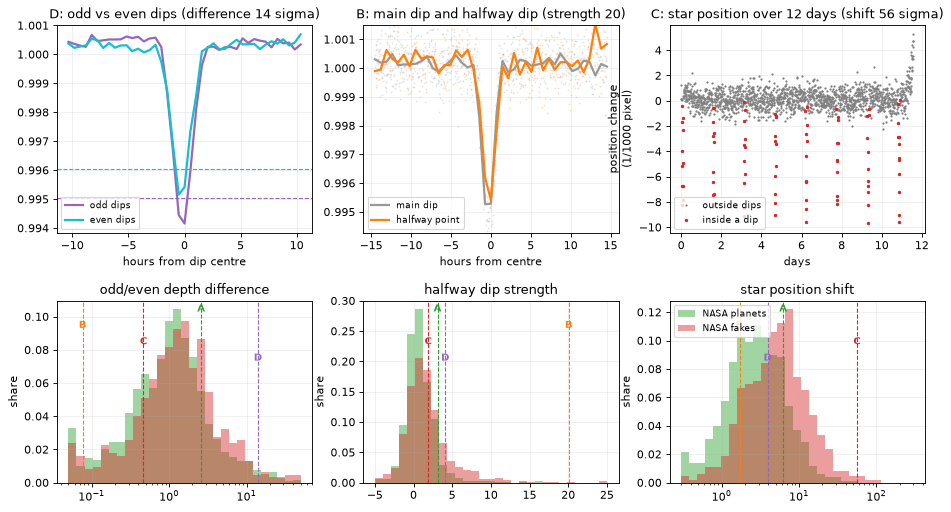

In [14]:
fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['oe', 'half', 'pos']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['odd_even_sigma', 'secondary_snr', 'centroid_snr']], gridspec_kw={'top': .42, 'bottom': .07})

def folded_hours(k, shift=0.0):
    # 10-minute measurement data of example k, as hours from the dip (or from `shift` orbits after it)
    r, dm = ex[k], mdata[k]
    x = phase_offset(dm['time'], r.period, r.t0 + shift * r.period) * 24
    return x, dm['flux'], np.rint((dm['time'] - r.t0) / r.period).astype(int)

ax = top['oe']
r = ex['D']; x, fl, cyc = folded_hours('D'); win3 = np.abs(x) < 2.5 * r.duration_h
events = pd.DataFrame(vet['D']['events'])
for parity, lab, c in [(1, 'odd dips', 'tab:purple'), (0, 'even dips', 'tab:cyan')]:
    s = win3 & (cyc % 2 == parity)
    b, _ = m7.binned(x[s], fl[s], -2.5 * r.duration_h, 2.5 * r.duration_h, 41)
    ax.plot(np.linspace(-2.5, 2.5, 41) * r.duration_h, b, color=c, lw=2, label=lab)
    e = events[events.cycle % 2 == parity]
    depth, _ = weighted_mean(e.depth.values, e.depth_error.values)
    ax.axhline(1 - depth, color=c, ls='--', lw=1)
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'D: odd vs even dips (difference {r.odd_even_sigma:.0f} sigma)', xlabel='hours from dip centre')

ax = top['half']
r = ex['B']
lowest = []
for shift, lab, c in [(0, 'main dip', '0.6'), (0.5, 'halfway point', COLORS['B'])]:
    x, fl, _ = folded_hours('B', shift); s = np.abs(x) < 2.5 * r.duration_h
    ax.plot(x[s], fl[s], '.', ms=1.5, alpha=.2, color=c)
    b, _ = m7.binned(x[s], fl[s], -2.5 * r.duration_h, 2.5 * r.duration_h, 41)
    ax.plot(np.linspace(-2.5, 2.5, 41) * r.duration_h, b, color=c, lw=2, label=lab)
    lowest.append(b.min())
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'B: main dip and halfway dip (strength {r.secondary_snr:.0f})', xlabel='hours from centre',
       ylim=(min(lowest) - 0.001, 1.0015))

ax = top['pos']
r, dm = ex['C'], mdata['C']
inside = np.abs(phase_offset(dm['time'], r.period, r.t0)) < r.duration_h / 48
outside = np.abs(phase_offset(dm['time'], r.period, r.t0)) > r.duration_h / 24
col = max(['centroid1', 'centroid2'], key=lambda c: abs(np.nanmean(dm[c][inside]) - np.nanmean(dm[c][outside])))
s = dm['time'] < dm['time'].min() + 12
ax.plot(dm['time'][s] - dm['time'][0], dm[col][s] * 1000, '.', ms=2, color='0.5', label='outside dips')
ax.plot(dm['time'][s & inside] - dm['time'][0], dm[col][s & inside] * 1000, '.', ms=4, color=COLORS['C'], label='inside a dip')
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'C: star position over 12 days (shift {r.centroid_snr:.0f} sigma)', xlabel='days',
       ylabel='position change\n(1/1000 pixel)')

class_hist(bottom['odd_even_sigma'], 'odd_even_sigma', 0.05, 50, log=True)
class_hist(bottom['secondary_snr'], 'secondary_snr', -5, 25)
class_hist(bottom['centroid_snr'], 'centroid_snr', 0.3, 300, log=True)
bottom['centroid_snr'].legend(fontsize=8, loc='upper left')
plt.show()

- D's odd dips are visibly deeper than its even dips. Dashed lines: the measured average depths. They are measured on the middle half of each dip, so they sit a little above the very bottom.
- B dims again exactly halfway round its orbit, almost as deeply: two similar stars taking turns to hide each other.
- C's measured position jumps at every single dip.

In the histograms, fakes have a long tail of large values on all three. But many fakes look clean here, and some planets show a few sigma too, so none of these is a perfect test on its own.

### Group 4: how consistently the dip shows up

- **Dips seen per month.** Number of dips with data, divided by the number of months (sectors). Mostly set by the period, but it also lets the model put the other numbers in context.
- **Share of dips clear on their own.** For each single dip: its depth divided by its own uncertainty. A dip with 3 or more counts as "clear". A real planet's dips should mostly be clear (if they are deep enough); a fake built from a couple of glitches won't be.
- **Share of data blocks that found it.** The search runs separately on each block of up to 4 consecutive months. A real signal should be found in every block; a one-off glitch only in one.

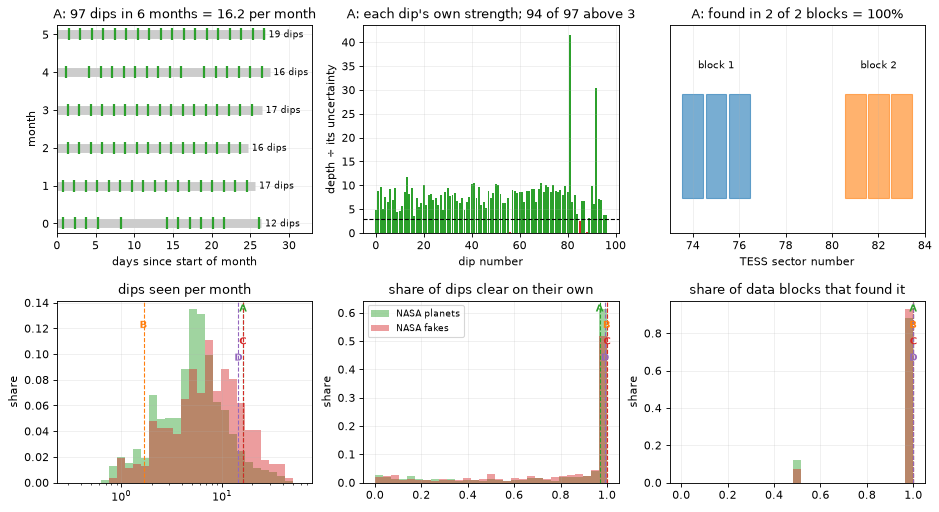

In [15]:
fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['months', 'events', 'blocks']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['transits_per_sector', 'significant_event_fraction', 'chunk_fraction']],
                            gridspec_kw={'top': .42, 'bottom': .07})

ax = top['months']
dip_times = np.array([e['epoch_btjd'] for e in vet['A']['events']])
for i, ts in enumerate(d['time'] for d in mparts['A']):
    ax.plot([0, ts.max() - ts.min()], [i, i], color='0.8', lw=8, solid_capstyle='butt')
    mine = dip_times[(dip_times >= ts.min()) & (dip_times <= ts.max())]
    ax.plot(mine - ts.min(), np.full(len(mine), i), '|', color=COLORS['A'], ms=10, mew=2)
    ax.text(ts.max() - ts.min() + 0.5, i, f'{len(mine)} dips', va='center', fontsize=8)
ax.set(title=f'A: {len(dip_times)} dips in {len(mparts["A"])} months = {A.transits_per_sector:.1f} per month',
       xlabel='days since start of month', ylabel='month', xlim=(0, 33), yticks=range(len(mparts['A'])))

ax = top['events']
snr = np.array([e['snr'] for e in vet['A']['events']])
ax.bar(range(len(snr)), snr, color=np.where(snr >= 3, COLORS['A'], 'tab:red'))
ax.axhline(3, color='k', ls='--', lw=1)
ax.set(title=f"A: each dip's own strength; {(snr >= 3).sum()} of {len(snr)} above 3",
       xlabel='dip number', ylabel='depth ÷ its uncertainty')

ax = top['blocks']
sector_no = lambda p: int(p.split('-s')[1][:4])
for b, grp in enumerate(m5.chunks(paths['A'])):
    for p in grp:
        ax.add_patch(plt.Rectangle((sector_no(p) - 0.45, 0.2), 0.9, 0.6, color=f'C{b}', alpha=.6))
    mid = np.mean([sector_no(p) for p in grp])
    ax.text(mid, 0.95, f'block {b + 1}', ha='center', fontsize=9)
secs = [sector_no(p) for p in paths['A']]
ax.set(xlim=(min(secs) - 1, max(secs) + 1), ylim=(0, 1.2), yticks=[], xlabel='TESS sector number',
       title=f'A: found in {A.n_chunks_found} of {A.chunks:.0f} blocks = {A.chunk_fraction:.0%}')

class_hist(bottom['transits_per_sector'], 'transits_per_sector', 0.3, 60, log=True)
class_hist(bottom['significant_event_fraction'], 'significant_event_fraction', 0, 1)
class_hist(bottom['chunk_fraction'], 'chunk_fraction', 0, 1)
bottom['significant_event_fraction'].legend(fontsize=8, loc='upper left')
plt.show()

Most dips in the hard set, planet or fake, score near 100% on the last two. They matter mainly for the easy fakes (noise and glitches), and they give the model context.

### All 12 for our examples

In [16]:
meas = pd.DataFrame({f'{k} ({VERDICT[r.label]})': [r[c] for c in PLAIN] for k, r in ex.items()}, index=list(PLAIN.values()))
display(meas.round(2))

,A (known planet),B (fake),C (fake),D (fake)
time between dips (days),1.49,13.71,1.54,1.55
dip length (hours),1.91,5.81,1.90,4.14
dip depth (parts per million),19146.50,1518.39,4050.75,2634.57
search peak height (per dip),3.32,6.11,4.79,2.27
stands out from noise (per dip),10.22,15.21,18.27,9.45
"stands out from slow, wavy noise (per dip)",6.69,11.45,15.43,3.79
odd/even depth difference,2.60,0.08,0.47,14.01
halfway dip strength,3.11,20.09,1.87,4.08
star position shift,6.26,1.70,55.98,3.92
dips seen per month,16.17,1.67,16.00,14.50


The numbers match the pictures: B has a strong halfway dip, C a large position shift, D a large odd/even difference. A's warning-sign numbers are small, but its *size* numbers (depth, how clearly it stands out) are what the pictures alone can't show.

### Why give the model both pictures and numbers?

- The pictures are rescaled, so they **lose size and noise**: a crisp 2% dip and a barely-there 0.05% dip both go from 0 to -1. The numbers keep depth, length, period and how clearly the dip stands out.
- The numbers only **summarise** shape (one number for "halfway dip"). The pictures keep the full shape: U vs V, slopes, exactly where a shift happens.

We test this in section 7.

*Where we are: **stage 6** (the model).*


## 7. The model, in plain terms

**An everyday comparison.** Think of a new fruit inspector. They are shown thousands of fruits, each already labelled "ripe" or "unripe" by an expert. At first they guess at random. After every guess they are told the right answer, and they adjust what they pay attention to (colour, softness, spots). After many rounds they get good at it, even on fruit they have never seen.

Our network is the inspector. The fruits are dips; the expert labels are NASA's verdicts; "what it pays attention to" is about 100,000 adjustable numbers (*weights*) inside the network.

### The training loop

1. **Guess**: the network scores a batch of 128 dips.
2. **Compare** each score with NASA's answer.
3. **Penalty**: a number that is small when the guess is right and confident, and large when it is confidently wrong.
4. **Nudge** every weight a tiny bit in the direction that makes the penalty smaller.
5. **Repeat** for all batches. One pass through all training dips is one **round**.

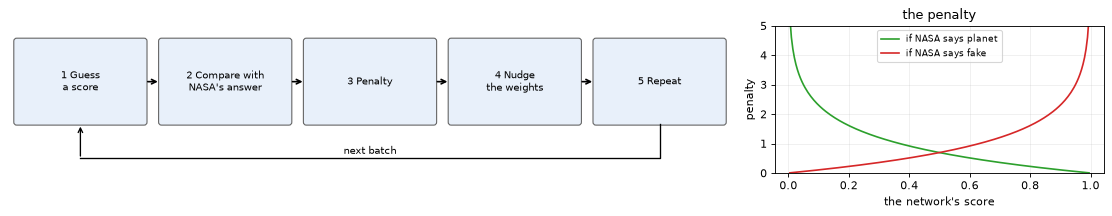

In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 2.8), gridspec_kw={'width_ratios': [2.2, 1]})
flow(a1, ['1 Guess\na score', "2 Compare with\nNASA's answer", '3 Penalty', '4 Nudge\nthe weights', '5 Repeat'], y=0.62, h=0.55)
a1.plot([4.5, 4.5, 0.5], [0.33, 0.1, 0.1], color='k', lw=1.2)
a1.annotate('', xy=(0.5, 0.33), xytext=(0.5, 0.1), arrowprops=dict(arrowstyle='->', lw=1.2))
a1.text(2.5, 0.13, 'next batch', ha='center', fontsize=9)
a1.set_ylim(0, 1)
s = np.linspace(0.005, 0.995, 200)
a2.plot(s, -np.log(s), color='tab:green', label='if NASA says planet')
a2.plot(s, -np.log(1 - s), color='tab:red', label='if NASA says fake')
a2.set(xlabel="the network's score", ylabel='penalty', title='the penalty', ylim=(0, 5))
a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

Right: if NASA says "planet", a score near 1 costs almost nothing; a score near 0 costs a lot. The reverse for fakes. (This penalty is called *log loss*.)

**Holding some stars aside.** A network can *memorise* its training dips instead of learning general rules. To catch that, we hide 15% of the training stars. They are never used for nudging. After every round we check the penalty on them. When it stops improving for 15 rounds, training stops and we keep the best version.

Now we train one network, using every star **except** group 0 and our four example stars, so A, B, C and D are unseen.

trained on 1182 dips, checked on 209 held-aside dips, 63 rounds, 9 s; 101,921 weights


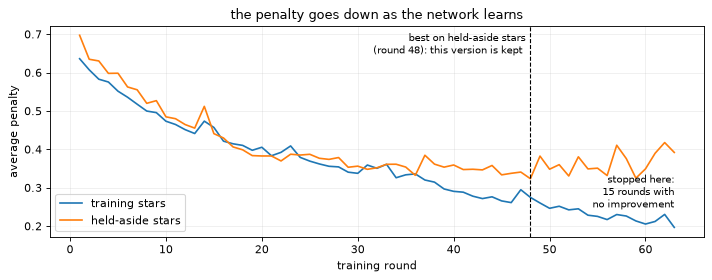

In [18]:
views = {k: np.clip(npz[k][df.view_row], -10, 10) for k in ['global'] + m8.LOCAL}
g = torch.as_tensor(views['global'][:, None])                   # whole orbit: 1 picture x 201 points
l = torch.as_tensor(np.stack([views[k] for k in m8.LOCAL], 1))  # close-ups: 5 pictures x 61 points
y = torch.as_tensor(df.y.values.astype(np.float32))
train = np.flatnonzero((df.fold.values != 0) & ~df.tic.isin([r.tic for r in ex.values()]).values)
x = torch.as_tensor(m8.features(df, train))                     # 12 numbers (rescaled) + 12 'missing' flags
fit, val = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0)
                .split(train, groups=df.tic.values[train]))    # 15% of training stars held aside

torch.manual_seed(0)
untrained = m8.ShapeNet(x.shape[1]).eval()                      # same starting point as the trained one
history = []
t_start = time.time()
net = m8.train_one(g, l, x, y, train[fit], train[val], seed=0, history=history).eval()
history = np.array(history)
best = history[:, 1].argmin()
print(f'trained on {len(fit)} dips, checked on {len(val)} held-aside dips, {len(history)} rounds, '
      f'{time.time() - t_start:.0f} s; {sum(p.numel() for p in net.parameters()):,} weights')

fig, ax = plt.subplots(figsize=(9, 3.6))
rounds = np.arange(1, len(history) + 1)
ax.plot(rounds, history[:, 0], color='tab:blue', label='training stars')
ax.plot(rounds, history[:, 1], color='tab:orange', label='held-aside stars')
ax.axvline(best + 1, color='k', ls='--', lw=1)
ax.text(best + 0.5, 0.97, f'best on held-aside stars\n(round {best + 1}): this version is kept ', va='top', ha='right',
        fontsize=9, transform=ax.get_xaxis_transform())
ax.text(len(history), 0.3, f'stopped here:\n{m8.PATIENCE} rounds with\nno improvement', va='top', ha='right', fontsize=9,
        transform=ax.get_xaxis_transform())
ax.set(xlabel='training round', ylabel='average penalty', title='the penalty goes down as the network learns')
ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

Both penalties fall quickly at first. Later the training stars keep improving while the held-aside stars level off: from there on the network is mostly memorising its training dips. So we stop and keep the version from the best round.

### Before and after training

Scores for the **unseen** group-0 dips in the hard set: first from the network before any training (random weights), then after.

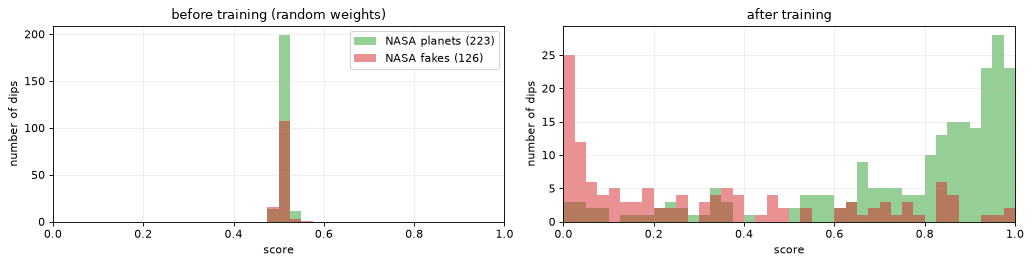

In [19]:
test = np.flatnonzero((df.fold.values == 0) & df.hard.values)
with torch.no_grad():
    before = torch.sigmoid(untrained(g[test], l[test], x[test])).numpy()
    after = torch.sigmoid(net(g[test], l[test], x[test])).numpy()
y_test = df.y.values[test]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, s, title in [(axes[0], before, 'before training (random weights)'), (axes[1], after, 'after training')]:
    for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        ax.hist(s[y_test == yy], np.linspace(0, 1, 41), alpha=.5, color=c, label=f'{lab} ({(y_test == yy).sum()})')
    ax.set(title=title, xlabel='score', ylabel='number of dips', xlim=(0, 1))
axes[0].legend()
plt.tight_layout(); plt.show()

Before training, every dip gets about the same score: the network knows nothing. After training, the planets pile up near 1. The fakes spread out and mostly score lower, but quite a few still score high: those are the fakes that look most like planets.

### Grading, part 1: ranking quality (ROC AUC)

Pick one real planet and one fake at random. How often does the planet get the higher score? That fraction is the **ROC AUC**. 0.5 = coin flip; 1 = every planet above every fake.

Below: each dot is one unseen dip. Lines join 40 random planet-fake pairs: green if the planet scored higher, red if not.

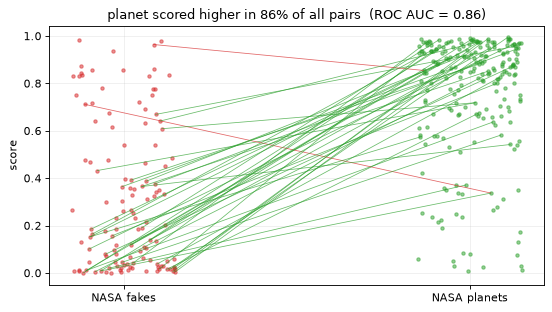

In [20]:
pl, fk = after[y_test == 1], after[y_test == 0]
pair_share = ((pl[:, None] > fk[None, :]).mean() + 0.5 * (pl[:, None] == fk[None, :]).mean())
auc = roc_auc_score(y_test, after)
assert np.isclose(pair_share, auc)

rng = np.random.default_rng(0)
xp, xf = 1 + rng.uniform(-.15, .15, len(pl)), rng.uniform(-.15, .15, len(fk))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xf, fk, '.', color='tab:red', alpha=.5); ax.plot(xp, pl, '.', color='tab:green', alpha=.5)
for i, j in zip(rng.integers(len(pl), size=40), rng.integers(len(fk), size=40)):
    ax.plot([xf[j], xp[i]], [fk[j], pl[i]], color='tab:green' if pl[i] > fk[j] else 'tab:red', lw=.7, alpha=.7)
ax.set(xticks=[0, 1], xticklabels=['NASA fakes', 'NASA planets'], ylabel='score',
       title=f'planet scored higher in {pair_share:.0%} of all pairs  (ROC AUC = {auc:.2f})')
plt.tight_layout(); plt.show()

### Grading, part 2: planets caught at the old rules' false-alarm rate

Before this model, the project used fixed rules (e.g. "search peak height at least 7"). Those rules let through a certain share of fakes. Fair comparison: set the model's cutoff so it lets through **the same share of fakes**, and count how many planets each one catches.

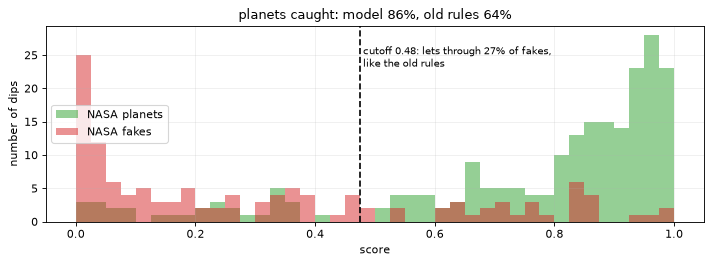

In [21]:
mask = np.zeros(len(df), bool); mask[test] = True
s_all = np.zeros(len(df)); s_all[test] = after
stats, _ = m6.fold_stats(df, s_all, np.zeros(len(df), int), mask)
rules = df.rules_pass.values[test]
fake_rate = rules[y_test == 0].mean()
cut = np.quantile(fk, 1 - fake_rate)
assert np.isclose((pl > cut).mean(), stats.model_planets_caught)

fig, ax = plt.subplots(figsize=(9, 3.4))
for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
    ax.hist(after[y_test == yy], np.linspace(0, 1, 41), alpha=.5, color=c, label=lab)
ax.axvline(cut, color='k', ls='--')
ax.text(cut, ax.get_ylim()[1] * .9, f' cutoff {cut:.2f}: lets through {fake_rate:.0%} of fakes,\n'
        f' like the old rules', fontsize=9, va='top')
ax.set(xlabel='score', ylabel='number of dips', title=f'planets caught: model {stats.model_planets_caught:.0%}, '
       f'old rules {stats.rules_planets_caught:.0%}')
ax.legend(loc='center left')
plt.tight_layout(); plt.show()

### Grading, part 3: plain accuracy, and why it can mislead

Call everything above 0.5 a planet. Then count right and wrong answers.

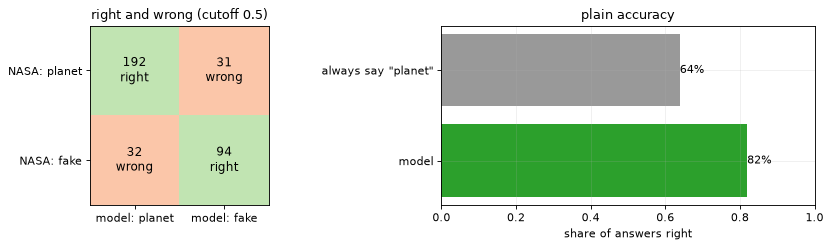

In [22]:
called = after > 0.5
grid = pd.DataFrame([[(called & (y_test == 1)).sum(), (~called & (y_test == 1)).sum()],
                     [(called & (y_test == 0)).sum(), (~called & (y_test == 0)).sum()]],
                    index=['NASA: planet', 'NASA: fake'], columns=['model: planet', 'model: fake'])
accuracy = (called == y_test).mean()
always = (y_test == 1).mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2))
a1.imshow([[1, 0], [0, 1]], cmap='RdYlGn', vmin=-.5, vmax=1.5, alpha=.5)
for i in range(2):
    for j in range(2):
        a1.text(j, i, f"{grid.iat[i, j]}\n{'right' if i == j else 'wrong'}", ha='center', va='center', fontsize=11)
a1.set(xticks=[0, 1], xticklabels=grid.columns, yticks=[0, 1], yticklabels=grid.index, title='right and wrong (cutoff 0.5)')
a1.grid(False)
bars = a2.barh(['model', 'always say "planet"'], [accuracy, always], color=['tab:green', '0.6'])
a2.bar_label(bars, fmt='%.0f%%', labels=[f'{v:.0%}' for v in [accuracy, always]])
a2.set(xlim=(0, 1), xlabel='share of answers right', title='plain accuracy')
plt.tight_layout(); plt.show()

The bottom-left cell is the costly mistake: fakes the model calls planets. A higher cutoff (as in part 2) trades a few planets for far fewer fakes.

About two thirds of the hard set are planets. So a "model" that always says "planet" is already right about 64% of the time, while catching zero fakes. Plain accuracy hides that. Ranking quality (part 1) and planets-caught-at-a-fixed-false-alarm-rate (part 2) don't have this problem, so those are the numbers we trust.

### Pictures, numbers, or both?

The full experiment, from the pipeline's stored results: all 5 groups, each scored by models that never saw it (5 networks averaged per group). Three models, ranking quality on the hard set:

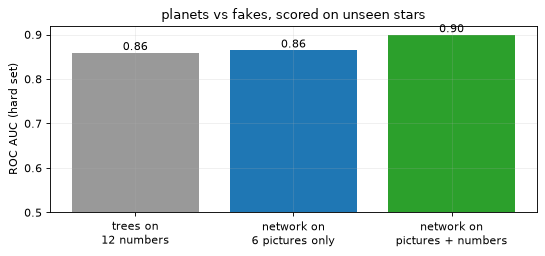

At the old rules' false-alarm rate: old rules catch 60% of planets; trees on 12 numbers: 83%, network on 6 pictures only: 86%, network on pictures + numbers: 92%


In [23]:
results = {}
for col, name in [('gbt', 'trees on\n12 numbers'), ('views', 'network on\n6 pictures only'),
                  ('views_features', 'network on\npictures + numbers')]:
    results[name], _ = m6.fold_stats(df, df[col].values, df.fold.values, df.hard.values)
fig, ax = plt.subplots(figsize=(7, 3.3))
bars = ax.bar(list(results), [m.roc_auc for m in results.values()], color=['0.6', 'tab:blue', 'tab:green'])
ax.bar_label(bars, fmt='%.2f')
ax.set(ylim=(0.5, 0.92), ylabel='ROC AUC (hard set)', title='planets vs fakes, scored on unseen stars')
plt.tight_layout(); plt.show()
auc = [m.roc_auc for m in results.values()]
assert auc[2] > max(auc[:2])
rules = next(iter(results.values())).rules_planets_caught
print(f"At the old rules' false-alarm rate: old rules catch {rules:.0%} of planets; "
      + ', '.join(f"{n.replace(chr(10), ' ')}: {m.model_planets_caught:.0%}" for n, m in results.items()))

Pictures alone and numbers alone are about equally good. Together they rank best: each carries something the other lacks.

*Where we are: **stage 6** (the model).*


## 8. A look inside the network

The model is a *convolutional neural network* (CNN). Instead of looking at all 61 points at once, it slides many small **pattern detectors** (5 points wide) along each picture and notes where each one matches.

1. **Two readers.** One reads the whole-orbit picture. The other reads the five close-ups stacked together, so it can compare them slot by slot.
2. **Layers of detectors.** The first layer spots tiny patterns (a step, a notch). Later layers combine those into bigger ones.
3. **Summary.** Each detector's strongest response in each quarter of the picture is kept.
4. **Combine.** Those are joined with the 12 numbers and turned into one score from 0 to 1.

### First-layer pattern detectors

The weights that 4 first-layer detectors apply to the close-up picture (the 4 that rely on it most). They are simple shapes. Nothing here "knows" about planets; that comes from combining many of them.

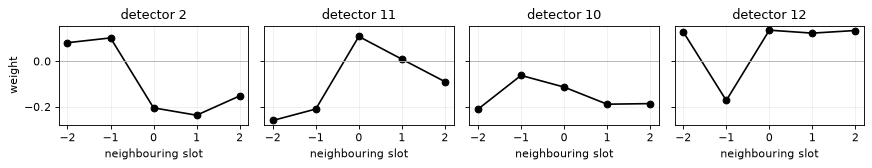

In [24]:
conv1 = net.loc[0]                              # first layer of the close-up reader
W = conv1.weight.detach()[:, 0]                 # weights applied to the close-up picture: 16 x 5
pick = torch.argsort(W.norm(dim=1), descending=True)[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(11, 2.2), sharey=True)
for ax, i in zip(axes, pick):
    ax.plot(range(-2, 3), W[i], 'o-', color='k')
    ax.axhline(0, color='0.7', lw=.8)
    ax.set(title=f'detector {i}', xticks=range(-2, 3), xlabel='neighbouring slot')
axes[0].set_ylabel('weight')
plt.tight_layout(); plt.show()

### Where on the dip each detector lights up

Slide each detector along the close-up of A (planet) and B (two stars). The response is how well the 5 points around each slot match the detector (negative matches are set to 0).

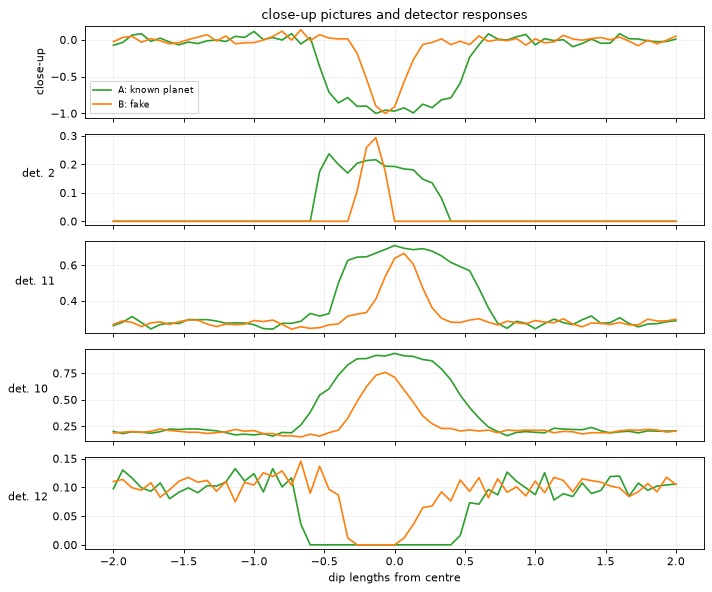

In [25]:
def response(k):
    s = torch.as_tensor(snap[k]['local'], dtype=torch.float32)[None, None]
    return torch.relu(torch.nn.functional.conv1d(s, W[:, None], conv1.bias.detach(), padding=2))[0]

fig, axes = plt.subplots(len(pick) + 1, 1, figsize=(9, 7.5), sharex=True)
for k in ['A', 'B']:
    axes[0].plot(x_local, snap[k]['local'], color=COLORS[k], label=f'{k}: {VERDICT[ex[k].label]}')
    r = response(k)
    for ax, i in zip(axes[1:], pick):
        ax.plot(x_local, r[i], color=COLORS[k])
        ax.set_ylabel(f'det. {i}', rotation=0, ha='right')
axes[0].set(title='close-up pictures and detector responses', ylabel='close-up')
axes[0].legend(loc='lower left', fontsize=8)
axes[-1].set_xlabel('dip lengths from centre')
plt.tight_layout(); plt.show()

Most of these detectors fire wherever the picture is low, i.e. inside the dip. For the planet (A) the response is a **wide plateau** (the U's flat floor); for the two-star pair (B) a **narrow spike**. So even the first layer turns the shape into "how wide and flat is the low part". Later layers combine such responses across all five close-ups; that part is spread over thousands of weights and can't be drawn as one picture.

### What each input contributes

Score each example three ways: as is; with its pictures swapped for the **average pictures** of all training dips; and with its numbers swapped for **average values**. This asks: what does this example's own shape, or its own numbers, add?

In [26]:
g_avg, l_avg = g[train].mean(0, keepdim=True), l[train].mean(0, keepdim=True)
x_avg = torch.zeros(1, x.shape[1])   # numbers were rescaled on the training dips, so 0 = average

def score(i, own_pictures=True, own_numbers=True):
    with torch.no_grad():
        return torch.sigmoid(net(g[i] if own_pictures else g_avg, l[i] if own_pictures else l_avg,
                                 x[i] if own_numbers else x_avg)).item()

rows = {}
for k, r in ex.items():
    i = [df.index[(df.tic == r.tic) & (df.signal == r.signal)][0]]
    rows[f'{k} ({VERDICT[r.label]})'] = {'full score': score(i),
                                         'average pictures instead': score(i, own_pictures=False),
                                         'average numbers instead': score(i, own_numbers=False)}
contrib = pd.DataFrame(rows).T
display(contrib.round(4))
own_pics, own_nums = contrib['average numbers instead'], contrib['average pictures instead']
assert own_nums.iloc[0] < 0.5 < own_pics.iloc[0]                 # A: its pictures carry it
assert (own_nums.iloc[1:] < own_pics.iloc[1:]).all()             # fakes: their numbers do more

,full score,average pictures instead,average numbers instead
A (known planet),0.8514,0.0653,0.9550
B (fake),0.0029,0.0029,0.3161
C (fake),0.0086,0.0080,0.2881
D (fake),0.0029,0.0061,0.1397


- **A (planet)**: with average pictures, its score drops below 0.5; with average numbers it stays high. A's own dip *shape* is what convinces the network. (The trees, which see only numbers, called A a fake.)
- **B, C, D (fakes)**: with only their own pictures (average numbers), the network is much less sure they are fakes. With only their own numbers (average pictures), their scores are already lower. For these fakes, the numbers (halfway dip, position shift, odd/even difference) do most of the work.

So the two inputs help in different cases: pictures rescue planets whose numbers look odd, and numbers catch fakes whose shape looks fine.

This is one network with one random start; the stored scores in section 1 average 5 networks per group, so the numbers differ a little.

*Where we are: **stage 7** (ranked list).*


## Recap: the whole pipeline

1. **Download**: TESS measures each star's brightness every 2 minutes, a month (sector) at a time.
2. **Clean**: slow drifts are divided out, so only short dips remain.
3. **Search**: try thousands of periods; the one where the dips line up gives a tall peak (its height is the SDE).
4. **Search again**: hide those dips and search once more, to catch a second signal.
5. **Pictures**: folding stacks every dip on top of each other so noise averages out. That gives 6 pictures (whole orbit, close-up, odd, even, halfway, star position), rescaled to show shape only.
6. **Numbers**: 12 measurements in four groups: the dip itself (period, length, depth), how clearly it stands out (SDE, SNR, wavy-noise SNR, all per dip), warning signs (odd/even, halfway dip, position shift) and consistency (dips per month, share of clear dips, share of blocks).
7. **Model**: slides small pattern detectors over the pictures, adds the numbers, and outputs a score from 0 to 1.
8. **Training**: guess, compare with NASA's verdict, penalty, nudge, repeat; held-aside stars tell it when to stop.
9. **Grading** on stars it never saw: pictures + numbers rank planets above fakes better than either alone, and at the old rules' false-alarm rate it catches far more planets than the rules did (section 7). Plain accuracy misleads, because two thirds of the dips are planets.
10. **Ranked list**: all dips sorted by score; the top ones are the best candidates for a human to check.

In [27]:
print(f'notebook ran in {time.time() - START:.0f} s')

notebook ran in 46 s
